# 04 - Evaluation and Interpretation

Metrics and plots use actual predictions on the held-out 2012 period.

In [1]:
from pathlib import Path
import sys
import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
from preprocessing import load_hourly_data, chronological_split
from evaluation import evaluate_models, feature_importance, save_results, largest_errors
df = load_hourly_data(ROOT / 'dataset' / 'hour.csv')
_, test_data = chronological_split(df)
models = {name: joblib.load(ROOT / 'models' / f'{name}.joblib') for name in ['random_forest', 'xgboost']}
metrics, predictions = evaluate_models(models, test_data)
save_results(metrics, predictions, ROOT / 'outputs')
largest = largest_errors(models, test_data, predictions)
largest.to_csv(ROOT / 'outputs' / 'largest_prediction_errors.csv', index=False)
display(metrics)

,model,MAE,MSE,RMSE,R2,mean_residual,largest_absolute_error
0,random_forest,88.775107,15491.995195,124.466844,0.644995,84.294572,569.783333
1,xgboost,89.677490,15465.121094,124.358840,0.645611,84.942843,563.187378


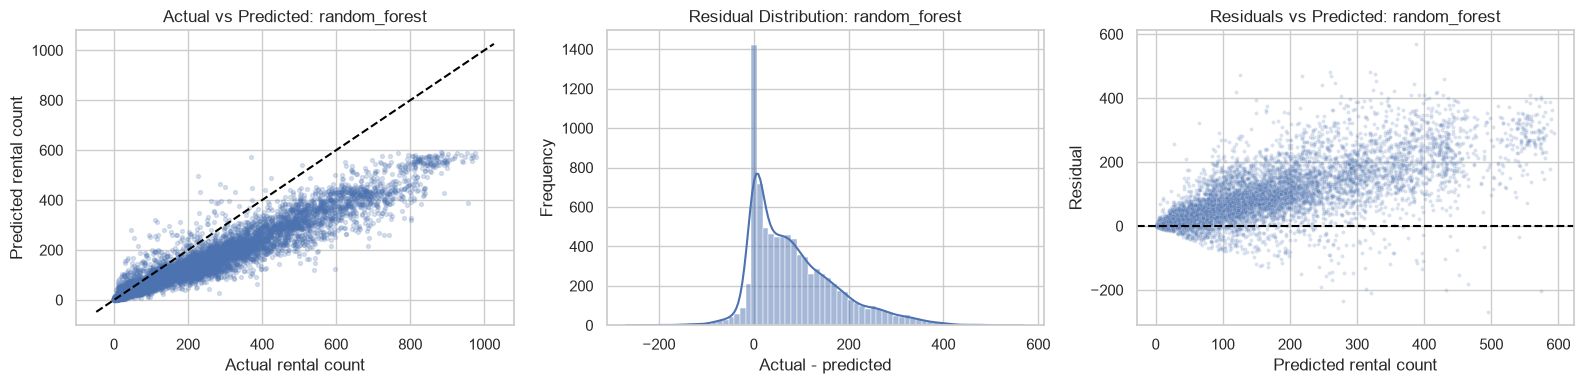

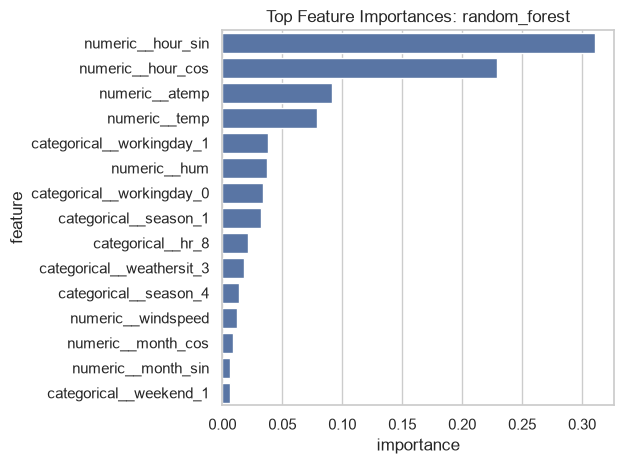

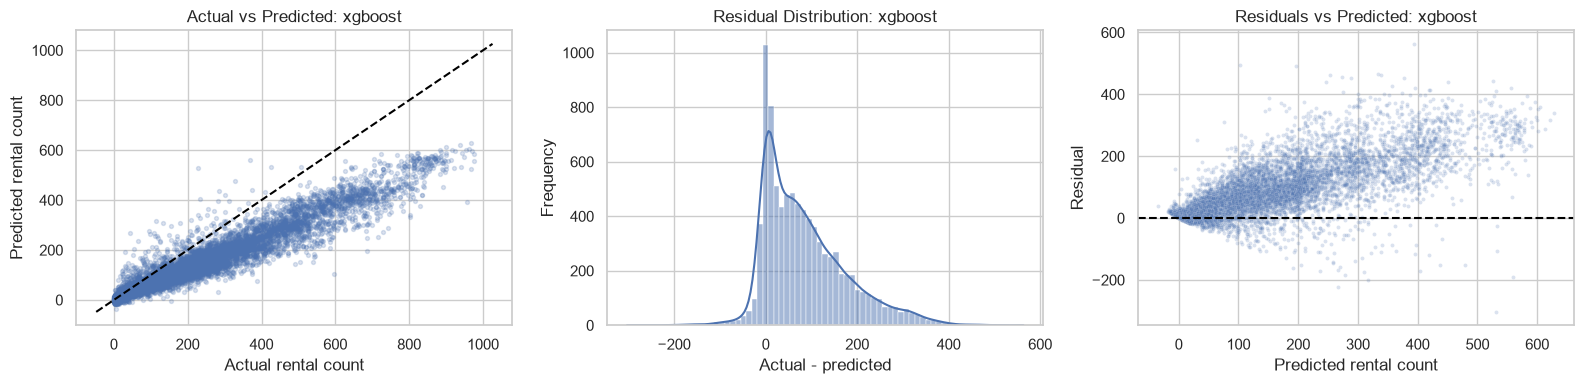

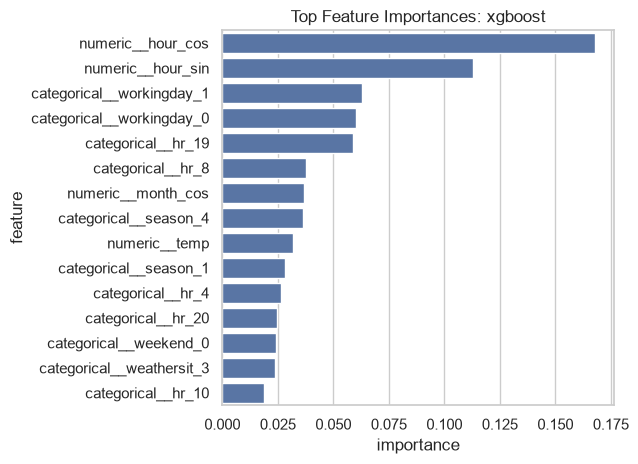

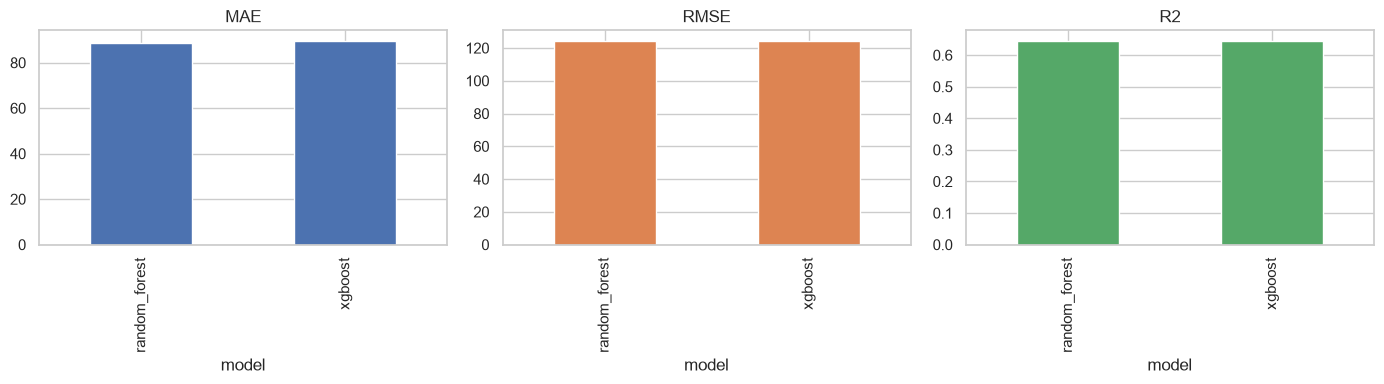

,model,MAE,MSE,RMSE,R2,mean_residual,largest_absolute_error
1,xgboost,89.677490,15465.121094,124.358840,0.645611,84.942843,563.187378
0,random_forest,88.775107,15491.995195,124.466844,0.644995,84.294572,569.783333


In [2]:
sns.set_theme(style='whitegrid')
for name in models:
    residuals = predictions['cnt'] - predictions[f'{name}_prediction']
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    axes[0].scatter(predictions['cnt'], predictions[f'{name}_prediction'], alpha=.2, s=8)
    limits = axes[0].get_xlim(); axes[0].plot(limits, limits, '--', color='black')
    axes[0].set(title=f'Actual vs Predicted: {name}', xlabel='Actual rental count', ylabel='Predicted rental count')
    sns.histplot(residuals, kde=True, ax=axes[1]); axes[1].set(title=f'Residual Distribution: {name}', xlabel='Actual - predicted', ylabel='Frequency')
    sns.scatterplot(x=predictions[f'{name}_prediction'], y=residuals, alpha=.2, s=8, ax=axes[2])
    axes[2].axhline(0, linestyle='--', color='black'); axes[2].set(title=f'Residuals vs Predicted: {name}', xlabel='Predicted rental count', ylabel='Residual')
    fig.tight_layout(); fig.savefig(ROOT / 'outputs' / f'{name}_diagnostics.png', dpi=150); plt.show()
    importance = feature_importance(models[name], name).head(15)
    importance.to_csv(ROOT / 'outputs' / f'{name}_feature_importance.csv', index=False)
    sns.barplot(data=importance, y='feature', x='importance'); plt.title(f'Top Feature Importances: {name}'); plt.tight_layout(); plt.savefig(ROOT / 'outputs' / f'{name}_feature_importance.png', dpi=150); plt.show()
comparison = metrics.set_index('model')[['MAE', 'RMSE', 'R2']]
comparison.plot(kind='bar', subplots=True, layout=(1, 3), figsize=(14, 4), legend=False)
plt.tight_layout(); plt.savefig(ROOT / 'outputs' / 'model_comparison.png', dpi=150); plt.show()
display(metrics.sort_values('RMSE'))